# Packages

In [18]:
import pandas as pd #pandas: untuk manipulasi dan analisis data
import numpy as np #numpy: untuk operasi numerik.
import matplotlib.pyplot as plt #matplotlib.pyplot: untuk membuat visualisasi grafis.
from sklearn.preprocessing import LabelEncoder #LabelEncoder dari sklearn.preprocessing: Digunakan untuk mengubah nilai kategori menjadi nilai numerik.

from sklearn.model_selection import train_test_split #train_test_split dari sklearn.model_selection: Digunakan untuk membagi dataset menjadi set pelatihan dan pengujian.
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold #cross_val_score, KFold dari sklearn.model_selection: Digunakan untuk melakukan validasi silang (cross-validation).
from sklearn.metrics import accuracy_score #accuracy_score dari sklearn.metrics: Digunakan untuk menghitung akurasi model.

# Data

In [19]:
from google.colab import files
uploaded = files.upload()

Saving personality_dataset.csv to personality_dataset (2).csv


In [20]:
import pandas as pd
dataset = pd.read_csv('personality_dataset.csv')  # ganti dengan nama file setelah upload

In [21]:
dataset.shape # memberikan informasi tentang ukuran dataset dalam bentuk tupel

(2900, 8)

In [22]:
dataset.columns # mengembalikan daftar nama kolom dalam dataset.

Index(['Time_spent_Alone', 'Stage_fear', 'Social_event_attendance',
       'Going_outside', 'Drained_after_socializing', 'Friends_circle_size',
       'Post_frequency', 'Personality'],
      dtype='object')

In [23]:
dataset.dtypes # memberikan informasi tentang tipe data (data type) dari setiap kolom dalam dataset.

,0
Time_spent_Alone,float64
Stage_fear,object
Social_event_attendance,float64
Going_outside,float64
Drained_after_socializing,object
Friends_circle_size,float64
Post_frequency,float64
Personality,object


In [24]:
dataset.info() # memberikan informasi yang lebih rinci tentang dataset, termasuk jumlah non-null values, tipe data, dan penggunaan memori.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2900 entries, 0 to 2899
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Time_spent_Alone           2837 non-null   float64
 1   Stage_fear                 2827 non-null   object 
 2   Social_event_attendance    2838 non-null   float64
 3   Going_outside              2834 non-null   float64
 4   Drained_after_socializing  2848 non-null   object 
 5   Friends_circle_size        2823 non-null   float64
 6   Post_frequency             2835 non-null   float64
 7   Personality                2900 non-null   object 
dtypes: float64(5), object(3)
memory usage: 181.4+ KB


# Eksplorasi Data

In [25]:
dataset.nunique() # memberikan jumlah nilai unik (distinct) dalam setiap kolom.

,0
Time_spent_Alone,12
Stage_fear,2
Social_event_attendance,11
Going_outside,8
Drained_after_socializing,2
Friends_circle_size,16
Post_frequency,11
Personality,2


In [26]:
dataset

,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
0,4.0,No,4.0,6.0,No,13.0,5.0,Extrovert
1,9.0,Yes,0.0,0.0,Yes,0.0,3.0,Introvert
2,9.0,Yes,1.0,2.0,Yes,5.0,2.0,Introvert
3,0.0,No,6.0,7.0,No,14.0,8.0,Extrovert
4,3.0,No,9.0,4.0,No,8.0,5.0,Extrovert
...,...,...,...,...,...,...,...,...
2895,3.0,No,7.0,6.0,No,6.0,6.0,Extrovert
2896,3.0,No,8.0,3.0,No,14.0,9.0,Extrovert
2897,4.0,Yes,1.0,1.0,Yes,4.0,0.0,Introvert
2898,11.0,Yes,1.0,NaN,Yes,2.0,0.0,Introvert


## Cek Missing Value

In [27]:
dataset.isnull().sum()

,0
Time_spent_Alone,63
Stage_fear,73
Social_event_attendance,62
Going_outside,66
Drained_after_socializing,52
Friends_circle_size,77
Post_frequency,65
Personality,0


In [28]:
missing_cols = dataset.columns[dataset.isnull().any()].tolist()
print(missing_cols)

['Time_spent_Alone', 'Stage_fear', 'Social_event_attendance', 'Going_outside', 'Drained_after_socializing', 'Friends_circle_size', 'Post_frequency']


In [29]:
dataset = dataset.dropna()

In [30]:
dataset.shape

(2477, 8)

In [31]:
dataset

,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
0,4.0,No,4.0,6.0,No,13.0,5.0,Extrovert
1,9.0,Yes,0.0,0.0,Yes,0.0,3.0,Introvert
2,9.0,Yes,1.0,2.0,Yes,5.0,2.0,Introvert
3,0.0,No,6.0,7.0,No,14.0,8.0,Extrovert
4,3.0,No,9.0,4.0,No,8.0,5.0,Extrovert
...,...,...,...,...,...,...,...,...
2892,9.0,Yes,2.0,0.0,Yes,1.0,2.0,Introvert
2895,3.0,No,7.0,6.0,No,6.0,6.0,Extrovert
2896,3.0,No,8.0,3.0,No,14.0,9.0,Extrovert
2897,4.0,Yes,1.0,1.0,Yes,4.0,0.0,Introvert


## Deskriptif Data

In [32]:
dataset.describe() # Menampilkan statistik deskriptif (mean, std, min, max, dll.) dari dataset.

,Time_spent_Alone,Social_event_attendance,Going_outside,Friends_circle_size,Post_frequency
count,2477.000000,2477.000000,2477.000000,2477.000000,2477.000000
mean,4.522406,3.939039,3.013726,6.239806,3.559548
std,3.491162,2.900044,2.257239,4.311365,2.927397
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,2.000000,1.000000,3.000000,1.000000
50%,4.000000,3.000000,3.000000,5.000000,3.000000
75%,8.000000,6.000000,5.000000,10.000000,6.000000
max,11.000000,10.000000,7.000000,15.000000,10.000000


## Cek Outlier

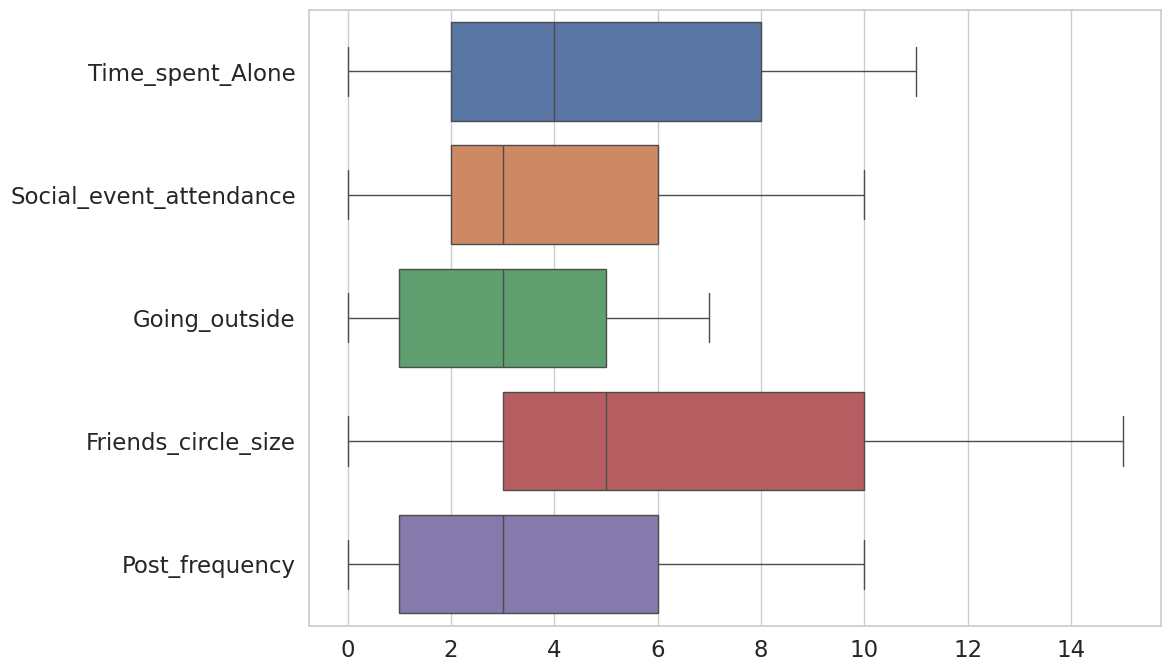

In [33]:
import seaborn as sns
%matplotlib inline

sns.set(rc={'figure.figsize':(11,8)}, font_scale=1.5, style='whitegrid')

# tips = sns.load_dataset(dataset)
sns.boxplot(data=dataset, orient="h");

## Distribusi Kelas Target atau Peubah Respon

In [34]:
dataset['Personality']

,Personality
0,Extrovert
1,Introvert
2,Introvert
3,Extrovert
4,Extrovert
...,...
2892,Introvert
2895,Extrovert
2896,Extrovert
2897,Introvert


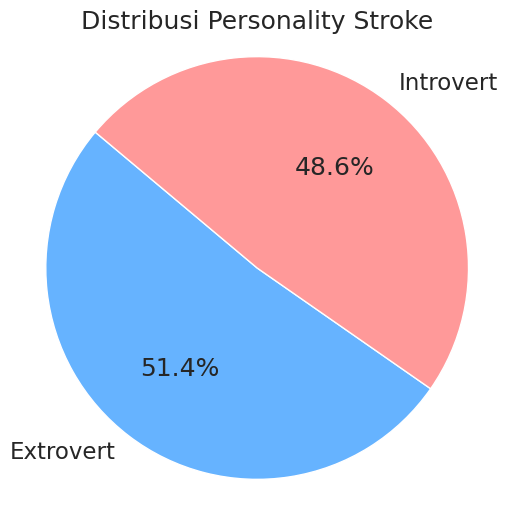

In [35]:
import matplotlib.pyplot as plt

# Hitung jumlah masing-masing kategori
Personality_counts = dataset['Personality'].value_counts()

# Plot pie chart
plt.figure(figsize=(6, 6))
plt.pie(Personality_counts, labels=Personality_counts.index, autopct='%1.1f%%', startangle=140, colors=['#66b3ff','#ff9999'])
plt.title('Distribusi Personality Stroke')
plt.axis('equal')  # Biar bentuk lingkarannya bulat
plt.show()

## Korelasi X terhadap Y

### Korelasi X Kategorik ke Y

In [36]:
import pandas as pd
from scipy.stats import chi2_contingency

# Daftar variabel numerik yang dikecualikan
numeric_cols = ['Time_spent_Alone', 'Social_event_attendance', 'Going_outside', 'Friends_circle_size', 'Post_frequency']

# Variabel target
target = 'Personality'

# Semua kolom selain numerik dan target
categorical_cols = [col for col in dataset.columns if col not in numeric_cols + [target]]

# Menyimpan hasil uji
chi2_results = []

for col in categorical_cols:
    # Cross tabulasi
    ct = pd.crosstab(dataset[col], dataset[target])

    # Uji Chi-Square
    chi2, p, dof, expected = chi2_contingency(ct)

    # Simpan hasil
    chi2_results.append({
        'Variable': col,
        'Chi2': chi2,
        'p-value': p
    })

# Buat dataframe hasil
chi2_df = pd.DataFrame(chi2_results)

# Tampilkan hasil urut berdasarkan p-value terkecil
chi2_df = chi2_df.sort_values(by='p-value').reset_index(drop=True)
print(chi2_df)

                    Variable         Chi2  p-value
0                 Stage_fear  1790.102051      0.0
1  Drained_after_socializing  1790.102051      0.0


### Korelasi X Numerik terhadap Y

In [37]:
numerical_cols = ['Time_spent_Alone', 'Social_event_attendance', 'Going_outside', 'Friends_circle_size', 'Post_frequency']

from scipy.stats import ttest_ind

def ttest_eta(df, cat_col, num_col):
    groups = [group[num_col].values for _, group in df.groupby(cat_col)]
    t_stat, p_val = ttest_ind(*groups, equal_var=False)  # Welch's t-test
    # Eta squared
    grand_mean = df[num_col].mean()
    ss_between = sum(len(g) * (g.mean() - grand_mean)**2 for g in groups)
    ss_total = sum((df[num_col] - grand_mean)**2)
    eta_sq = ss_between / ss_total
    print(f"T-test {num_col} vs {cat_col} → t: {t_stat:.4f}, p-value: {p_val:.4f}, Eta Squared: {eta_sq:.4f}")

for num_col in numerical_cols:
    ttest_eta(dataset, 'Personality', num_col)

T-test Time_spent_Alone vs Personality → t: -48.9400, p-value: 0.0000, Eta Squared: 0.4938
T-test Social_event_attendance vs Personality → t: 51.0687, p-value: 0.0000, Eta Squared: 0.5097
T-test Going_outside vs Personality → t: 53.7407, p-value: 0.0000, Eta Squared: 0.5366
T-test Friends_circle_size vs Personality → t: 47.0265, p-value: 0.0000, Eta Squared: 0.4677
T-test Post_frequency vs Personality → t: 51.2174, p-value: 0.0000, Eta Squared: 0.5094


# Pra-Processing Data

## Pisahkan X dan Y

In [38]:
x = dataset.drop('Personality', axis=1)
x

,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency
0,4.0,No,4.0,6.0,No,13.0,5.0
1,9.0,Yes,0.0,0.0,Yes,0.0,3.0
2,9.0,Yes,1.0,2.0,Yes,5.0,2.0
3,0.0,No,6.0,7.0,No,14.0,8.0
4,3.0,No,9.0,4.0,No,8.0,5.0
...,...,...,...,...,...,...,...
2892,9.0,Yes,2.0,0.0,Yes,1.0,2.0
2895,3.0,No,7.0,6.0,No,6.0,6.0
2896,3.0,No,8.0,3.0,No,14.0,9.0
2897,4.0,Yes,1.0,1.0,Yes,4.0,0.0


In [39]:
y = dataset["Personality"]
y

,Personality
0,Extrovert
1,Introvert
2,Introvert
3,Extrovert
4,Extrovert
...,...
2892,Introvert
2895,Extrovert
2896,Extrovert
2897,Introvert


In [40]:
y = y.map({'Introvert': 0, 'Extrovert': 1}).values

In [41]:
y

array([1, 0, 0, ..., 1, 0, 1])

## Categorical Encoding

In [42]:
x = pd.get_dummies(x, drop_first=True)
x

,Time_spent_Alone,Social_event_attendance,Going_outside,Friends_circle_size,Post_frequency,Stage_fear_Yes,Drained_after_socializing_Yes
0,4.0,4.0,6.0,13.0,5.0,False,False
1,9.0,0.0,0.0,0.0,3.0,True,True
2,9.0,1.0,2.0,5.0,2.0,True,True
3,0.0,6.0,7.0,14.0,8.0,False,False
4,3.0,9.0,4.0,8.0,5.0,False,False
...,...,...,...,...,...,...,...
2892,9.0,2.0,0.0,1.0,2.0,True,True
2895,3.0,7.0,6.0,6.0,6.0,False,False
2896,3.0,8.0,3.0,14.0,9.0,False,False
2897,4.0,1.0,1.0,4.0,0.0,True,True


## Cek Multikol di X

In [43]:
x.dtypes

,0
Time_spent_Alone,float64
Social_event_attendance,float64
Going_outside,float64
Friends_circle_size,float64
Post_frequency,float64
Stage_fear_Yes,bool
Drained_after_socializing_Yes,bool


In [44]:
import numpy as np
import pandas as pd

def group_columns_by_prefix(columns):
    groups = {}
    for col in columns:
        if '_' in col:
            prefix = col.split('_')[0]
        else:
            prefix = col  # misal numerik tanpa _
        groups.setdefault(prefix, []).append(col)
    return groups

def calculate_gvif_groups(X, groups):
    corr = X.corr()
    inv_corr = np.linalg.inv(corr.values)
    cols = corr.columns

    gvif_results = {}

    for var, cols_group in groups.items():
        idx_group = [cols.get_loc(c) for c in cols_group]
        idx_others = [i for i in range(len(cols)) if i not in idx_group]

        inv_corr_sub = inv_corr[np.ix_(idx_others, idx_others)]

        det_full = np.linalg.det(inv_corr)
        det_sub = np.linalg.det(inv_corr_sub)

        gvif = det_full / det_sub
        df = len(cols_group)

        adj_gvif = gvif**(1/(2*df)) if df > 1 else gvif

        gvif_results[var] = (gvif, adj_gvif)

    return gvif_results

# Misal x sudah get_dummies(drop_first=True)
groups = group_columns_by_prefix(x.columns)
gvif_vals = calculate_gvif_groups(x, groups)

print("GVIF per variabel (dengan penyesuaian df):")
for var, (gvif, adj_gvif) in gvif_vals.items():
    print(f"{var}: GVIF = {gvif:.4f}, Adjusted GVIF = {adj_gvif:.4f}")


GVIF per variabel (dengan penyesuaian df):
Time: GVIF = 0.9580, Adjusted GVIF = 0.9580
Social: GVIF = 0.9679, Adjusted GVIF = 0.9679
Going: GVIF = 0.9103, Adjusted GVIF = 0.9103
Friends: GVIF = 1.1098, Adjusted GVIF = 1.1098
Post: GVIF = 0.9268, Adjusted GVIF = 0.9268
Stage: GVIF = 1.0000, Adjusted GVIF = 1.0000
Drained: GVIF = 1.0000, Adjusted GVIF = 1.0000


## Splitting

In [45]:
from sklearn.model_selection import train_test_split
xTrain, xTest, yTrain, yTest = train_test_split(x, y, train_size=0.8, random_state=3, stratify=y)

In [46]:
from collections import Counter
print("Train distribution", Counter(yTrain))
print("Test distribution", Counter(yTest))

Train distribution Counter({np.int64(1): 1019, np.int64(0): 962})
Test distribution Counter({np.int64(1): 255, np.int64(0): 241})


## Persiapan data ke reglog

In [47]:
xTrain = xTrain.astype(float)
xTest = xTest.astype(float)


In [48]:
print(type(yTrain))
print(yTrain.shape)
print(type(xTrain))
print(xTrain.shape)
print(type(yTest))
print(yTest.shape)
print(type(xTest))
print(xTest.shape)

<class 'numpy.ndarray'>
(1981,)
<class 'pandas.core.frame.DataFrame'>
(1981, 7)
<class 'numpy.ndarray'>
(496,)
<class 'pandas.core.frame.DataFrame'>
(496, 7)


In [49]:
yTrain1d = yTrain.ravel()
yTest1d = yTest.ravel()

In [50]:
xTrain_np = xTrain.values
print(type(xTrain_np))  # <class 'numpy.ndarray'>
print(xTrain_np.shape)  # (4087, 22)
#xTrain_np = xTrain
xTest_np = xTest.values
print(type(xTest_np))  # <class 'numpy.ndarray'>
print(xTest_np.shape)  # (4087, 22)

<class 'numpy.ndarray'>
(1981, 7)
<class 'numpy.ndarray'>
(496, 7)


# Regresi Logistik dengan Gradient Descent

Iterasi 0, Cost: 0.70062
Iterasi 100, Cost: 0.44316
Iterasi 200, Cost: 0.37414
Iterasi 300, Cost: 0.34670
Iterasi 400, Cost: 0.33364
Iterasi 500, Cost: 0.32666
Iterasi 600, Cost: 0.32261
Iterasi 700, Cost: 0.32011
Iterasi 800, Cost: 0.31848
Iterasi 900, Cost: 0.31736
Iterasi 0, Cost: 0.71756
Iterasi 100, Cost: 0.44224
Iterasi 200, Cost: 0.37352
Iterasi 300, Cost: 0.34620
Iterasi 400, Cost: 0.33319
Iterasi 500, Cost: 0.32622
Iterasi 600, Cost: 0.32217
Iterasi 700, Cost: 0.31966
Iterasi 800, Cost: 0.31802
Iterasi 900, Cost: 0.31689
Iterasi 1000, Cost: 0.31608
Iterasi 1100, Cost: 0.31546
Iterasi 1200, Cost: 0.31498
Iterasi 1300, Cost: 0.31458
Iterasi 1400, Cost: 0.31424
Iterasi 1500, Cost: 0.31394
Iterasi 1600, Cost: 0.31368
Iterasi 1700, Cost: 0.31343
Iterasi 1800, Cost: 0.31321
Iterasi 1900, Cost: 0.31299
Iterasi 2000, Cost: 0.31279
Iterasi 2100, Cost: 0.31260
Iterasi 2200, Cost: 0.31241
Iterasi 2300, Cost: 0.31223
Iterasi 2400, Cost: 0.31206
Iterasi 2500, Cost: 0.31189
Iterasi 2600, Co

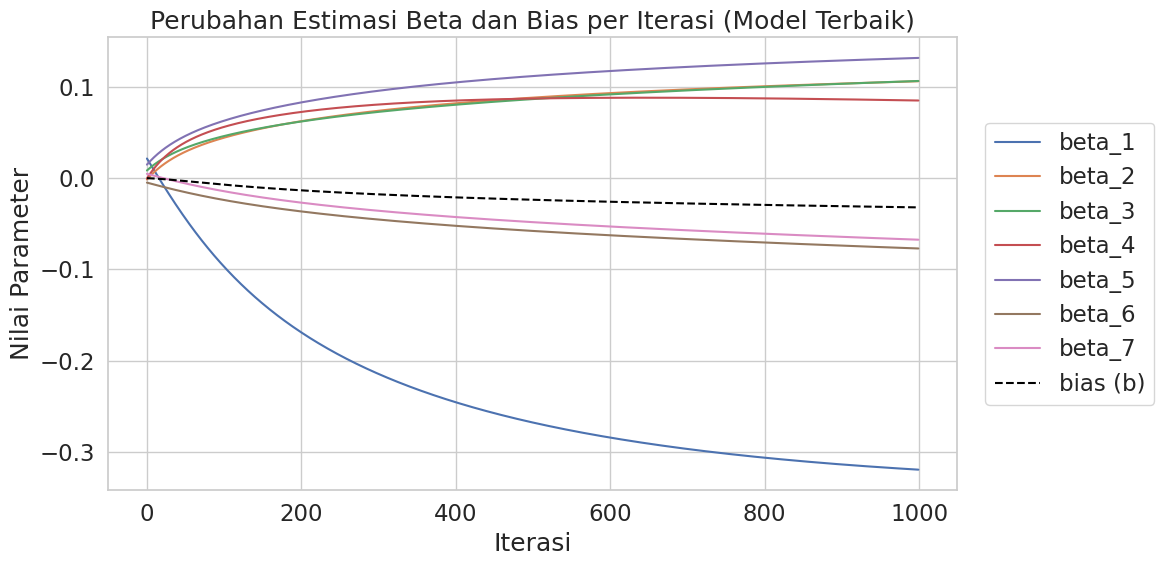

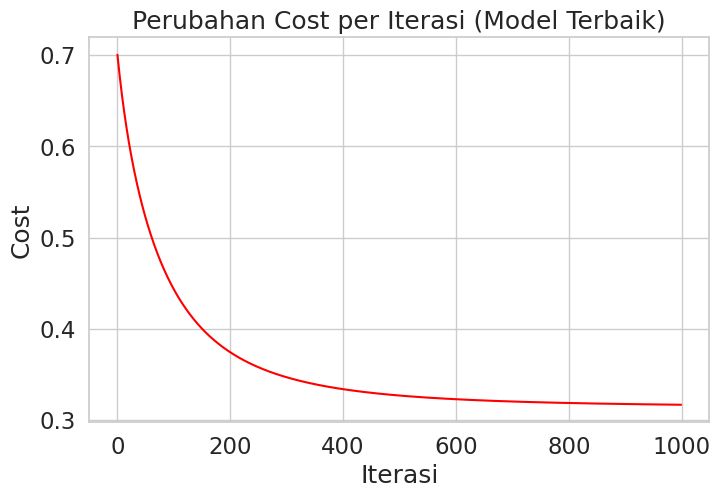

=== Persamaan Regresi Logistik ===
logit(p) = b + w1*x1 + w2*x2 + ... + w7*x7

b (intercept) = -0.03200
w1 = -0.31916
w2 = 0.10609
w3 = 0.10640
w4 = 0.08500
w5 = 0.13164
w6 = -0.07699
w7 = -0.06738

=== Persamaan Probabilitas (Sigmoid) ===
p = 1 / (1 + exp(-(-0.03200 + (-0.31916 * x1) + (0.10609 * x2) + (0.10640 * x3) + (0.08500 * x4) + (0.13164 * x5) + (-0.07699 * x6) + (-0.06738 * x7))))


In [52]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

class LogisticRegression:
    def __init__(self, x_train, y_train, w, b, learning_rate=0.01, n_iter=10000, threshold=0.5):
        self.x_train = x_train
        self.y_train = y_train
        self.w = w
        self.b = b
        self.learning_rate = learning_rate
        self.n_iter = n_iter
        self.threshold = threshold

        self.cost_history = []
        self.w_history = []
        self.b_history = []

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def compute_cost(self):
        n = len(self.y_train)
        z = np.dot(self.x_train, self.w) + self.b
        h = self.sigmoid(z)
        epsilon = 1e-5  # hindari log(0)
        cost = -(1/n) * (np.dot(self.y_train.T, np.log(h + epsilon)) + np.dot((1 - self.y_train).T, np.log(1 - h + epsilon)))
        return cost.flatten()[0]

    def gradient_descent(self):
        n = len(self.y_train)
        z = np.dot(self.x_train, self.w) + self.b
        h = self.sigmoid(z)
        error = h - self.y_train
        dw = (1/n) * np.dot(self.x_train.T, error)
        db = (1/n) * np.sum(error)
        self.w -= self.learning_rate * dw
        self.b -= self.learning_rate * db

    def train(self):
        for i in range(self.n_iter):
            self.gradient_descent()
            cost = self.compute_cost()
            self.cost_history.append(cost)
            self.w_history.append(self.w.copy())  # simpan salinan bobot
            self.b_history.append(self.b)

            if i % 100 == 0:
                print(f"Iterasi {i}, Cost: {cost:.5f}")

        # Konversi list history ke numpy array agar mudah plotting
        self.w_history = np.array(self.w_history).squeeze()
        self.b_history = np.array(self.b_history).squeeze()
        return self.w, self.b

    def predict_proba(self, x_test):
        z = np.dot(x_test, self.w) + self.b
        return self.sigmoid(z)

    def predict(self, x_test):
        proba = self.predict_proba(x_test)
        return (proba >= self.threshold).astype(int).flatten()


# --- LOOP TRAINING DENGAN KOMBINASI PARAMETER ---
learning_rates = [0.001, 0.01, 0.05, 0.2, 0.02]
iterations_list = [1000, 3000, 5000, 10000]
thresholds = [0.5]
results = []

for lr in learning_rates:
    for iters in iterations_list:
        for thresh in thresholds:
            w_init = np.random.normal(0, 0.01, (xTrain_np.shape[1], 1))
            b_init = 0.0

            model = LogisticRegression(
                x_train=xTrain_np,
                y_train=yTrain1d.reshape(-1, 1),
                w=w_init,
                b=b_init,
                learning_rate=lr,
                n_iter=iters,
                threshold=thresh
            )
            model.train()

            y_pred = model.predict(xTest_np)
            y_proba = model.predict_proba(xTest_np)

            acc = accuracy_score(yTest1d, y_pred)
            prec = precision_score(yTest1d, y_pred, zero_division=0)
            rec = recall_score(yTest1d, y_pred, zero_division=0)
            f1 = f1_score(yTest1d, y_pred, zero_division=0)
            auc = roc_auc_score(yTest1d, y_proba)

            results.append({
                'learning_rate': lr,
                'iterations': iters,
                'threshold': thresh,
                'accuracy': acc,
                'precision': prec,
                'recall': rec,
                'f1_score': f1,
                'auc': auc,
                'model': model
            })

best_result = max(results, key=lambda x: x['accuracy'])
best_trained_model = best_result['model']

print("\n=== Konfigurasi Terbaik (berdasarkan Akurasi) ===")
for k, v in best_result.items():
    if k != 'model':
        if isinstance(v, float):
            print(f"{k:12} : {v:.4f}")
        else:
            print(f"{k:12} : {v}")

# --- Plot perubahan parameter dan cost per iterasi ---
w_array = best_trained_model.w_history
b_array = best_trained_model.b_history

plt.figure(figsize=(12, 6))
for i in range(w_array.shape[1]):
    plt.plot(w_array[:, i], label=f'beta_{i+1}')
plt.plot(b_array, label='bias (b)', linestyle='--', color='black')
plt.xlabel('Iterasi')
plt.ylabel('Nilai Parameter')
plt.title('Perubahan Estimasi Beta dan Bias per Iterasi (Model Terbaik)')
plt.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(best_trained_model.cost_history, color='red')
plt.xlabel('Iterasi')
plt.ylabel('Cost')
plt.title('Perubahan Cost per Iterasi (Model Terbaik)')
plt.grid(True)
plt.show()

# --- Tampilkan persamaan regresi ---
w_flat = best_trained_model.w.flatten()
b = best_trained_model.b

print("=== Persamaan Regresi Logistik ===")
print("logit(p) = b + w1*x1 + w2*x2 + ... + w7*x7")
print(f"\nb (intercept) = {b:.5f}")
for i, coef in enumerate(w_flat):
    print(f"w{i+1} = {coef:.5f}")

terms = [f"({coef:.5f} * x{i+1})" for i, coef in enumerate(w_flat)]
equation = " + ".join(terms)
equation = f"p = 1 / (1 + exp(-({b:.5f} + {equation})))"

print("\n=== Persamaan Probabilitas (Sigmoid) ===")
print(equation)



=== Evaluasi Data Latih ===
Akurasi    : 0.9268
Precision  : 0.9379
Recall     : 0.9185
F1 Score   : 0.9281
ROC AUC    : 0.9036

=== Evaluasi Data Uji ===
Akurasi    : 0.9194
Precision  : 0.9424
Recall     : 0.8980
F1 Score   : 0.9197
ROC AUC    : 0.8897


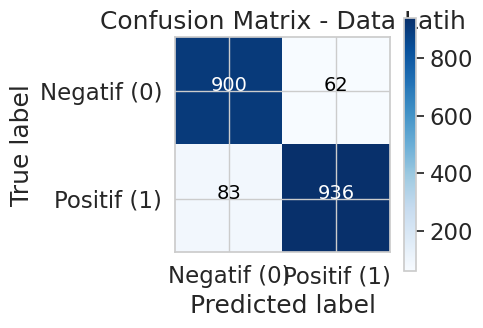

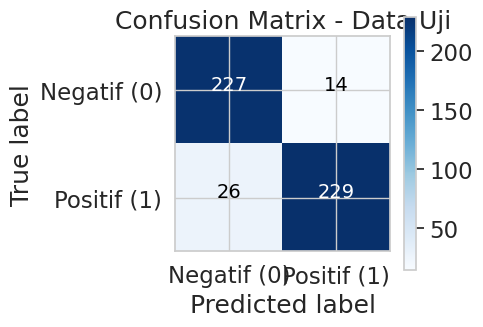

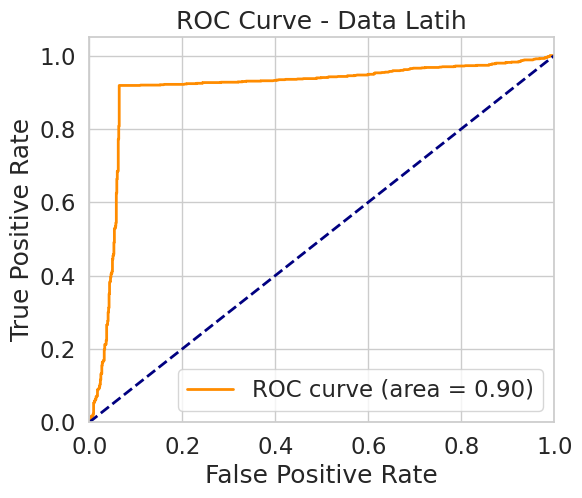

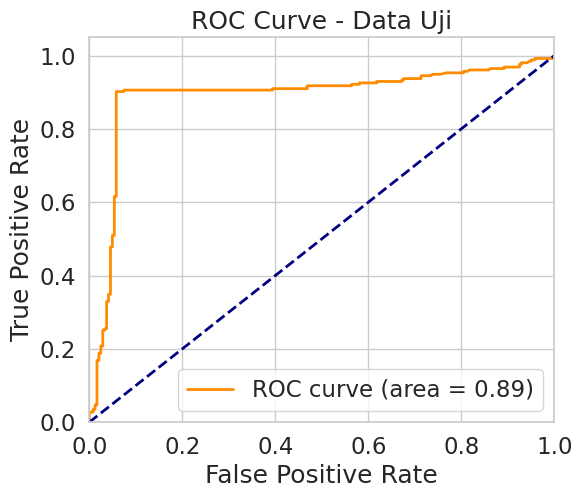

In [53]:
from sklearn.metrics import confusion_matrix, roc_curve, auc

# --- Prediksi pada data latih ---
y_train_pred = best_trained_model.predict(xTrain_np)
y_train_proba = best_trained_model.predict_proba(xTrain_np)

# --- Prediksi pada data uji ---
y_test_pred = best_trained_model.predict(xTest_np)
y_test_proba = best_trained_model.predict_proba(xTest_np)

# Fungsi untuk print metrik evaluasi
def print_metrics(y_true, y_pred, y_proba, data_name="Data"):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc_score = roc_auc_score(y_true, y_proba)
    print(f"\n=== Evaluasi {data_name} ===")
    print(f"Akurasi    : {acc:.4f}")
    print(f"Precision  : {prec:.4f}")
    print(f"Recall     : {rec:.4f}")
    print(f"F1 Score   : {f1:.4f}")
    print(f"ROC AUC    : {auc_score:.4f}")

# Print metrik untuk data latih dan uji
print_metrics(yTrain1d, y_train_pred, y_train_proba, "Data Latih")
print_metrics(yTest1d, y_test_pred, y_test_proba, "Data Uji")

# Fungsi menampilkan confusion matrix
def plot_confusion_matrix(y_true, y_pred, data_name="Data"):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5,4))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title(f"Confusion Matrix - {data_name}")
    plt.colorbar()
    tick_marks = np.arange(2)
    plt.xticks(tick_marks, ['Negatif (0)', 'Positif (1)'])
    plt.yticks(tick_marks, ['Negatif (0)', 'Positif (1)'])

    thresh = cm.max() / 2.
    for i, j in np.ndindex(cm.shape):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black",
                 fontsize=14)

    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    plt.show()

# Plot confusion matrix untuk data latih dan uji
plot_confusion_matrix(yTrain1d, y_train_pred, "Data Latih")
plot_confusion_matrix(yTest1d, y_test_pred, "Data Uji")

# Plot ROC Curve untuk data latih dan uji
def plot_roc_curve(y_true, y_proba, data_name="Data"):
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(6,5))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0,1], [0,1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve - {data_name}')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()

plot_roc_curve(yTrain1d, y_train_proba, "Data Latih")
plot_roc_curve(yTest1d, y_test_proba, "Data Uji")
